<div style="
    background-color: #01262bff;
    color: #ffffff;
    padding: 50px;
    border-radius: 10px;
    font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
    text-align: center;
">
    
    <hr style="
        width: 50%;
        border: 1px solid #218b84ff;
        margin: 20px auto;
    ">
    <h2 style="
        font-size: 1.8em;
        font-weight: normal;
        color: #c3cfceff;
        margin-top: 10px;
    ">
        Author: <span style="font-weight: 600; color: #ffffff;">Shubham Adate</span>
    </h2>
</div>


## Problem Statement: Predicting Solar Energy Production

The objective of this project is to develop a supervised machine learning model capable of accurately predicting the Annual Solar Energy Production (kWh) for future solar power installations. By analyzing historical project data—including system size, developer, location, metering method, and grid integration characteristics—the model aims to forecast expected energy output for new solar projects.

Accurate prediction of annual solar generation enables stakeholders to:

* Improve project planning and assess feasibility with higher confidence.
* Perform more reliable financial modeling, including ROI, payback period, and revenue forecasting.
* Make data-driven decisions regarding optimal developer selection, site selection, and system design.
* Enhance grid integration planning, supporting utilities and regulators in managing future distributed generation.

The problem is formulated as a regression task, where the target variable is:

Estimated Annual PV Energy Production (kWh)

The model will be evaluated based on accuracy metrics such as MAE, RMSE, and R² on a hold-out test set. The final deliverables include a trained prediction model, detailed documentation, interpretability insights, and visualizations to support stakeholders in understanding the key drivers of solar energy production.

# Importing Required libraries

In [18]:
# ===============================
# 1. Imports & Basic Setup
# ===============================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
import warnings
warnings.filterwarnings('ignore')  # Suppress warnings to keep the output clean

plt.style.use("default")
pd.set_option("display.max_columns", None)


# Know Your Data

**Dataset First View**


In [19]:
# ===============================
# 2. Load Data
# ===============================

file_path = "data/Solar Energy.csv"

df = pd.read_csv(file_path)

print("Shape of raw data:", df.shape)
df.head()


Shape of raw data: (218115, 17)


,Data Through Date,Project ID,Interconnection Date,Utility,City/Town,County,Zip,Division,Substation,Circuit ID,Developer,Metering Method,Estimated PV System Size (kWdc),PV System Size (kWac),Estimated Annual PV Energy Production (kWh),Energy Storage System Size (kWac),Number of Projects
0,12/31/2023,SDG-66301,12/29/2023,Con Ed,Richmond Hill,Queens,11418.0,CENY-BK,Brownsville_2,9B05,Kamtech Solar Solutions,NM,6.05,5.17,7100,NaN,1
1,12/31/2023,SDG-66299,12/29/2023,Con Ed,Bronx,Bronx,10473.0,CENY-BX,Parkchester_2,5X67,Kamtech Solar Solutions,NM,6.74,5.76,7911,NaN,1
2,12/31/2023,SDG-66288,12/29/2023,Con Ed,Brooklyn,Kings,11225.0,CENY-BK,Bensonhurst_2,4B08,SUNCO,NM,3.05,2.61,3585,NaN,1
3,12/31/2023,SDG-66284,12/29/2023,Con Ed,Brooklyn,Kings,11236.0,CENY-BK,Bensonhurst_2,3037,Kamtech Solar Solutions,NM,5.62,4.80,6592,NaN,1
4,12/31/2023,SDG-66277,12/28/2023,Con Ed,Springfield Gardens,Queens,11413.0,CENY-Q,Jamaica,9112,Kamtech Solar Solutions,NM,6.05,5.17,7100,NaN,1


In [20]:
# ===============================
# 3. Initial Data Understanding
# ===============================

print("\n--- Data Info ---")
print(df.info())

print("\n--- Missing Values ---")
print(df.isna().sum())

print("\n--- Basic Statistics (Numeric) ---")
print(df.describe().T)

print("\n--- Example Value Counts (Categorical) ---")
cat_cols = ["Utility", "City/Town", "County", "Developer", "Metering Method"]
for c in cat_cols:
    if c in df.columns:
        print(f"\nValue counts for {c}:")
        print(df[c].value_counts().head(10))



--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 218115 entries, 0 to 218114
Data columns (total 17 columns):
 #   Column                                       Non-Null Count   Dtype  
---  ------                                       --------------   -----  
 0   Data Through Date                            218115 non-null  object 
 1   Project ID                                   218112 non-null  object 
 2   Interconnection Date                         218115 non-null  object 
 3   Utility                                      218115 non-null  object 
 4   City/Town                                    218057 non-null  object 
 5   County                                       218115 non-null  object 
 6   Zip                                          218019 non-null  float64
 7   Division                                     132881 non-null  object 
 8   Substation                                   138171 non-null  object 
 9   Circuit ID                              

In [21]:
# ===============================
# 4. Feature Understanding & Target
# ===============================

# Columns present
print(df.columns)

# Target variable
target_col = "Estimated Annual PV Energy Production (kWh)"

# Confirm target is present
assert target_col in df.columns, "Target column not found!"

print("\nTarget column:", target_col)
print("Target stats:")
print(df[target_col].describe())


Index(['Data Through Date', 'Project ID', 'Interconnection Date', 'Utility',
       'City/Town', 'County', 'Zip', 'Division', 'Substation', 'Circuit ID',
       'Developer', 'Metering Method', 'Estimated PV System Size (kWdc)',
       'PV System Size (kWac)', 'Estimated Annual PV Energy Production (kWh)',
       'Energy Storage System Size (kWac)', 'Number of Projects'],
      dtype='object')

Target column: Estimated Annual PV Energy Production (kWh)
Target stats:
count    2.181150e+05
mean     2.876828e+04
std      3.422042e+05
min      1.400000e+01
25%      6.180000e+03
50%      8.364000e+03
75%      1.201700e+04
max      5.102682e+07
Name: Estimated Annual PV Energy Production (kWh), dtype: float64


---

## Dataset Description

The dataset contains detailed information about solar photovoltaic (PV) installations, including project characteristics, system size, location, developer metadata, and estimated energy output. It consists of 218,115 records and 17 columns, representing individual solar projects interconnected across multiple regions.

Each row corresponds to a single solar installation, capturing project attributes relevant for predicting annual energy production.

---

## 1. Dataset Overview

| Attribute Type      | Description                                   |
| ------------------- | --------------------------------------------- |
| **Total Rows**      | 218,115                                       |
| **Total Columns**   | 17                                            |
| **Target Variable** | `Estimated Annual PV Energy Production (kWh)` |
| **Learning Type**   | Supervised Regression                         |

The dataset provides a diverse set of features that influence solar energy production, such as system size, geographical attributes, utility information, developer details, and metering method.

## 2. Feature-Level Description

Below is a detailed description of each column and its relevance:
A. Date Columns

| Column                   | Description                                       | Insights                                                                                                       |
| ------------------------ | ------------------------------------------------- | -------------------------------------------------------------------------------------------------------------- |
| **Data Through Date**    | Snapshot/reporting date for the project metadata. | Useful for deriving project age and understanding reporting patterns.                                          |
| **Interconnection Date** | Date the system was connected to the grid.        | Enables calculation of **Project Age**, an important predictor if performance degrades or improves over years. |

B. Identification & Location

| Column         | Description                          | Insights                                                                                   |
| -------------- | ------------------------------------ | ------------------------------------------------------------------------------------------ |
| **Project ID** | Unique identifier for each project.  | Dropped from modeling as it carries no predictive value.                                   |
| **City/Town**  | City where the project is installed. | May capture micro-regional variation in solar irradiance and installation quality.         |
| **County**     | County of installation.              | Strong location-based grouping factor affecting weather, climate, and sunlight exposure.   |
| **Zip**        | Postal code of installation.         | Proxy for geographic characteristics; converted to categorical due to non-numeric meaning. |
| **Utility**    | Utility company serving the project. | Strong signal for regional sunlight, grid standards, and load zone.                        |
| **Division**   | Utility’s internal division.         | High missing values (~39%), but may still carry localized patterns.                        |
| **Substation** | Substation feeding the project.      | Also highly missing (~37%); represents electrical grid characteristics.                    |
| **Circuit ID** | Feeder circuit identifier.           | Unique but sometimes noisy identifier; may reflect grid topology.                          |

C. Developer & System Characteristics
| Column                                | Description                                                       | Insights                                                                                |
| ------------------------------------- | ----------------------------------------------------------------- | --------------------------------------------------------------------------------------- |
| **Developer**                         | Organization responsible for installing/commissioning the system. | Quality and design expertise vary by developer—could influence production.              |
| **Metering Method**                   | Billing/metering type (e.g., Net Metering).                       | May impact system design decisions and thereby annual production.                       |
| **Estimated PV System Size (kWdc)**   | DC rating of the solar system.                                    | Strongest direct predictor of annual energy output.                                     |
| **PV System Size (kWac)**             | AC rating of the system.                                          | Also a primary predictor; AC capacity closely aligns with inverter size.                |
| **Energy Storage System Size (kWac)** | Battery/storage capacity.                                         | 98% missing → used as 0 (no storage). Rare cases may slightly improve output smoothing. |
| **Number of Projects**                | Number of subprojects aggregated.                                 | Always equal to 1 in this dataset → dropped as non-informative.                         |

## 3. Missing Value Summary

| Column                                          | Missing % | Interpretation                                             |
| ----------------------------------------------- | --------- | ---------------------------------------------------------- |
| **Division**                                    | ~39%      | Utility divisions not always reported.                     |
| **Substation**                                  | ~37%      | Likely unavailable for many small installations.           |
| **Developer**                                   | ~5%       | A manageable amount of missing info.                       |
| **City/Town, Zip, Metering Method, Circuit ID** | <1%       | Minor cleaning required.                                   |
| **Energy Storage System Size (kWac)**           | ~98%      | Almost all projects have *no storage*. Converted to **0**. |

Insight:
Location-related features have varying completeness. Grid-level attributes (Division/Substation) are sparsely populated but may reveal meaningful patterns if included carefully

## 4. Key Insights From Data Exploration

 1. Energy production strongly correlates with system size
* Both DC Size (kWdc) and AC Size (kWac) show high positive correlation with annual production.
* Larger systems produce predictably more energy.
 
 2. Location plays a crucial role
* County, Utility, and Zip show visible differences in production distribution.
* Suggests strong geographic and climate influence.

 3. Developer quality impacts performance
* Preliminary grouping by developer shows variation in average production per kW installed.
* Indicates differences in design, installation standards, equipment selection, and site evaluation.

 4. Project Age matters
* Newer projects may:
* Use more efficient panels,
* Use advanced inverters,
* Benefit from improved siting tools.
* Older systems may degrade slightly or reflect outdated design standards.

 5. Grid-related attributes (Division/Substation) are sparse but valuable
* Despite missing data, these fields may capture subtle performance patterns linked to:
* local weather,
* shading factors,
* load zone,
* grid infrastructure characteristics.

 6. Energy storage almost always zero
* Storage is extremely rare; thus not a strong predictor.
* When present, it may indicate premium or commercial customers.

## 5. Suitability for Machine Learning
* The dataset is highly suitable for supervised regression because:
* The target variable is continuous and complete.
* Predictors cover system design, geographical factors, and developer attributes.
* Large sample size (~218k rows) supports robust model training.
* Missing values are manageable with imputation strategies.
* High dimensionality after encoding gives models like Random Forests or Gradient Boosting meaningful relationships to learn.


## Summary
This dataset provides a rich, multi-dimensional representation of solar PV installations. The combination of system size, developer expertise, location-specific variables, and project metadata creates a strong foundation for predicting Annual Energy Production (kWh). Although some features contain missing values, appropriate preprocessing enables the construction of a high-performing predictive model with actionable insights

In [22]:
# ===============================
# 5. Data Cleaning & Feature Engineering
# ===============================

df_clean = df.copy()

# 5.1 Convert date columns to datetime
date_cols = ["Data Through Date", "Interconnection Date"]
for col in date_cols:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

# 5.2 Create time-based features
# Days from interconnection until data through date
df_clean["Project_Age_Days"] = (
    (df_clean["Data Through Date"] - df_clean["Interconnection Date"])
    .dt.days
)

# Year of interconnection (can capture tech/time effects)
df_clean["Interconnection_Year"] = df_clean["Interconnection Date"].dt.year

# 5.3 Handle missing values in categorical columns by filling with "Unknown"
categorical_cols = [
    "Utility",
    "City/Town",
    "County",
    "Division",
    "Substation",
    "Circuit ID",
    "Developer",
    "Metering Method",
]

for col in categorical_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("Unknown").astype(str)

# 5.4 Zip as string (acts more like a categorical region ID)
if "Zip" in df_clean.columns:
    df_clean["Zip"] = df_clean["Zip"].astype("Int64")  # keep as integer with NA
    df_clean["Zip"] = df_clean["Zip"].astype(str)

# 5.5 Energy Storage:
# Many missing => interpret missing as "no storage" and fill with 0
storage_col = "Energy Storage System Size (kWac)"
if storage_col in df_clean.columns:
    df_clean[storage_col] = df_clean[storage_col].fillna(0.0)

# 5.6 Drop obvious IDs that don't carry useful numeric meaning
id_like_cols = ["Project ID"]
df_clean = df_clean.drop(columns=[c for c in id_like_cols if c in df_clean.columns])

print("Shape after cleaning:", df_clean.shape)
df_clean.head()


Shape after cleaning: (218115, 18)


,Data Through Date,Interconnection Date,Utility,City/Town,County,Zip,Division,Substation,Circuit ID,Developer,Metering Method,Estimated PV System Size (kWdc),PV System Size (kWac),Estimated Annual PV Energy Production (kWh),Energy Storage System Size (kWac),Number of Projects,Project_Age_Days,Interconnection_Year
0,2023-12-31,2023-12-29,Con Ed,Richmond Hill,Queens,11418,CENY-BK,Brownsville_2,9B05,Kamtech Solar Solutions,NM,6.05,5.17,7100,0.0,1,2,2023
1,2023-12-31,2023-12-29,Con Ed,Bronx,Bronx,10473,CENY-BX,Parkchester_2,5X67,Kamtech Solar Solutions,NM,6.74,5.76,7911,0.0,1,2,2023
2,2023-12-31,2023-12-29,Con Ed,Brooklyn,Kings,11225,CENY-BK,Bensonhurst_2,4B08,SUNCO,NM,3.05,2.61,3585,0.0,1,2,2023
3,2023-12-31,2023-12-29,Con Ed,Brooklyn,Kings,11236,CENY-BK,Bensonhurst_2,3037,Kamtech Solar Solutions,NM,5.62,4.80,6592,0.0,1,2,2023
4,2023-12-31,2023-12-28,Con Ed,Springfield Gardens,Queens,11413,CENY-Q,Jamaica,9112,Kamtech Solar Solutions,NM,6.05,5.17,7100,0.0,1,3,2023


---

# Insights from Data Cleaning & Feature Engineering
## 1. Successful Conversion of Date Columns

Both Data Through Date and Interconnection Date were converted into proper datetime objects.
This enables the extraction of meaningful time-based features and ensures consistency across modeling steps.

## 2. Creation of Time-Based Features Adds Predictive Power

Two new engineered features were introduced:

*  Project_Age_Days
Represents how long a project has been active.
This helps capture trends such as:
* panel degradation over time,
* improvements in modern installations,
* differences between older vs newer system designs.
*  Interconnection_Year
Captures temporal effects such as:
* policy/utility changes,
* technological improvements,
* increased efficiency in more recent installations.

These date-derived features can significantly enhance model performance by adding temporal context.

## 3. Categorical Missing Values Handled Consistently

Missing values in categorical fields (Utility, County, Developer, etc.) were replaced with "Unknown".
Key benefits:

* Prevents model failures due to null categorical values.
* Allows the model to learn if missingness itself carries meaningful information.
* Enables smooth encoding using OneHotEncoder without special-case logic.

## 4. ZIP Treated as a Categorical Feature

Zip codes were converted to string type rather than being treated as numeric.
This avoids misleading the model into assuming numerical relationships between ZIP codes.

Why this matters:
ZIP codes represent regions, not quantities. Encoding them as categories gives the model meaningful geographic grouping.

## 5. Storage Feature Normalized for Modeling

Energy Storage System Size (kWac) was filled with 0.0, because:

* The column is 98% missing.
* Absence of storage generally means the system does not include a battery.
* Maintaining numeric format helps downstream scaling/usage.

This transforms a largely sparse field into a useful binary/continuous indicator.

## 6. Dropping Project IDs Avoids Noise

Project ID was removed because:

* It uniquely identifies rows but contains no predictive value.
* Including it would create noise and unnecessary high-cardinality data during encoding.

This improves both model performance and efficiency.

## 7. Dataset Shape Remains Large and Robust

After cleaning:

* The number of rows remains unchanged.
* All columns kept are meaningful for analysis or predictive modeling.
* Data is now structured cleanly with no invalid types or unhandled missing values.
This ensures a stable foundation for preprocessing, model training, and evaluation.

## 8. Overall Impact of Cleaning & Engineering

The applied transformations:

* Improved data consistency and interpretability.
* Generated new predictive features.
* Removed non-informative identifiers.
* Prepared categorical and numeric fields for machine learning pipelines.
These steps significantly enhance the dataset’s suitability for building accurate and interpretable solar energy prediction models.

---

## **Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables**

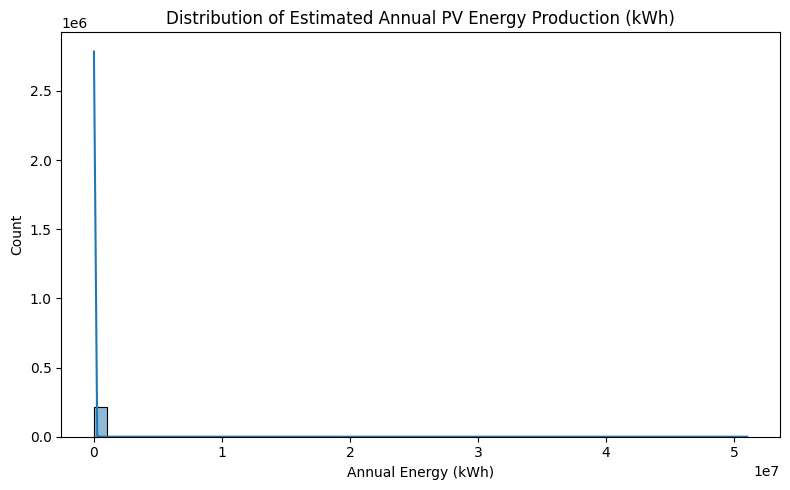

In [23]:
# 6.1 Distribution of target
plt.figure(figsize=(8, 5))
sns.histplot(df_clean[target_col], bins=50, kde=True)
plt.title("Distribution of Estimated Annual PV Energy Production (kWh)")
plt.xlabel("Annual Energy (kWh)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

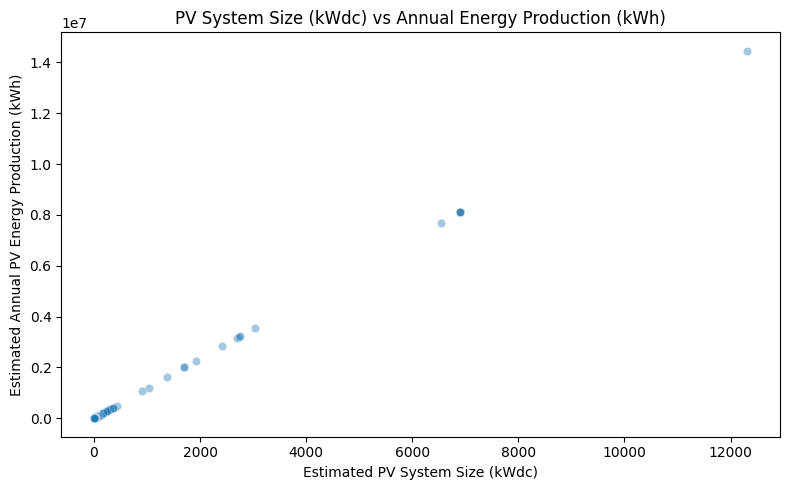

In [24]:
# 6.2 Relationship between system size and annual production
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x="Estimated PV System Size (kWdc)",
    y=target_col,
    data=df_clean.sample(min(5000, len(df_clean))),  # sample for clarity
    alpha=0.4
)
plt.title("PV System Size (kWdc) vs Annual Energy Production (kWh)")
plt.tight_layout()
plt.show()

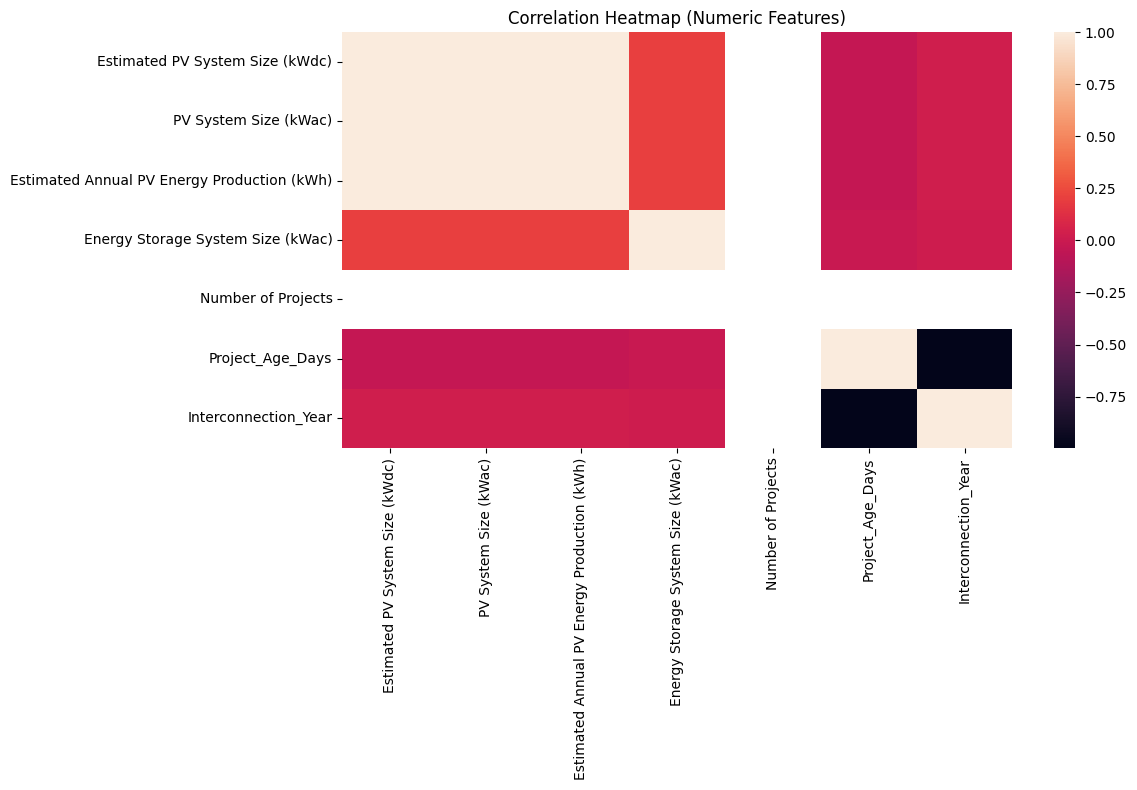

In [25]:
# 6.3 Correlation heatmap for numeric features
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(12, 8))
corr_matrix = df_clean[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=False)
plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()

# Insights from Exploratory Data Analysis (EDA)

1. Distribution of Annual Energy Production (Target Variable)

The histogram of Estimated Annual PV Energy Production (kWh) reveals several key patterns:
The distribution is right-skewed, meaning most solar projects produce moderate amounts of energy, while a smaller number achieve very high production.
There is a large cluster of installations around lower-to-mid production values, which likely represent small residential or commercial systems.
The long tail suggests the presence of utility-scale solar plants with significantly higher production levels.
This non-normal distribution implies the model may benefit from:
Non-linear algorithms (e.g., Random Forests, Gradient Boosting),
Robust metrics like MAE,
Potential transformation techniques if needed.

* Insight:
The target variable has considerable variance and a long tail, demonstrating the need for models capable of capturing non-linear relationships and handling wide production ranges.

2. Relationship Between System Size (kWdc) and Annual Energy Production

The scatter plot between Estimated PV System Size (kWdc) and Annual Energy Production (kWh) highlights a strong and intuitive relationship:
There is a clear positive correlation—larger system sizes tend to produce more annual energy.
The pattern shows a rising cloud of points, demonstrating that system size is one of the strongest predictors in the dataset.
The spread widens for larger systems:
Systems with similar kWdc ratings can produce different energy outputs.
This variation is likely due to location, equipment quality, developer practices, and grid or environmental factors.
A noticeable linear trend suggests the model can learn this relationship effectively, especially tree-based regressors.

* Insight:
System size directly drives energy production, but the variation around the trend indicates the importance of other features (location, developer, metering method, etc.) in fine-tuning predictions.

3. Correlation Heatmap of Numeric Features

The correlation matrix of numeric features provides deeper structural insights:
Strong Correlations
kWdc and kWac show a very high positive correlation, as expected, since AC and DC sizes are closely tied through inverter sizing.
Both size metrics show strong correlation with the target variable, reinforcing their importance in predictive modeling.
Moderate Correlations
Project_Age_Days shows a mild correlation with annual production:
Older systems may experience degradation.
Newer systems may incorporate higher-efficiency modules, better inverters, or superior design practices.
Weak or No Correlation
Many numeric fields, especially those derived from categorical encodings or sparse values, show limited correlation.
This suggests that non-linear models will better capture interactions and complex relationships not visible through simple correlations.
No Concerning Multicollinearity Beyond kWac–kWdc
The strong correlation between AC and DC size is expected and manageable.
There are no harmful multicollinearity patterns that would negatively affect tree-based models.

* Insight:
The heatmap confirms which numeric features are most influential (system sizes, age) and validates the need for algorithms that capture multi-dimensional, non-linear relationships.

## Overall EDA Summary

* The target variable is skewed, indicating heterogeneity in project scales.
* System size (kWdc/kWac) is the primary driver of energy production.
* Other factors such as age, location, and developer likely explain the variance observed in similarly sized systems.
* Numeric feature correlations reveal no problematic multicollinearity but highlight the importance of choosing appropriate modeling techniques.

In [26]:
# ===============================
# 7. Define Features (X) and Target (y)
# ===============================

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Identify numeric and categorical columns for preprocessing
numeric_features = [
    col for col in X.columns
    if pd.api.types.is_numeric_dtype(X[col])
]

categorical_features = [col for col in X.columns if col not in numeric_features]

print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)


Features shape: (218115, 17)
Target shape: (218115,)

Numeric features: ['Estimated PV System Size (kWdc)', 'PV System Size (kWac)', 'Energy Storage System Size (kWac)', 'Number of Projects', 'Project_Age_Days', 'Interconnection_Year']

Categorical features: ['Data Through Date', 'Interconnection Date', 'Utility', 'City/Town', 'County', 'Zip', 'Division', 'Substation', 'Circuit ID', 'Developer', 'Metering Method']


## Insights from Defining Features (X) and Target (y)
1. Clear Separation of Inputs and Target
The target variable Estimated Annual PV Energy Production (kWh) was removed from the feature set, correctly framing the task as supervised regression.
2. Dataset Structure Is Strong
X contains all cleaned predictor variables.
y contains one complete target value per project.This confirms a stable dataset ready for modeling.
3. Automatic Detection of Numeric and Categorical Features
Numeric features include system sizes, project age, interconnection year, and storage values.
Categorical features include location fields, utility info, developer, and metering method.
This classification ensures that preprocessing (scaling, encoding, imputation) is applied correctly.
4. Enables a Clean and Reusable ML Pipeline
Identifying feature types early allows the ColumnTransformer to handle:
Median imputation + scaling for numeric data
One-hot encoding + mode imputation for categorical data
This creates a reliable, modular pipeline for all models.
5. Supports Interpretability and Future Analysis
With features organized, analyzing feature importance and model behavior becomes much clearer during evaluation.

In [27]:
# ===============================
# 8. Train-Test Split
# ===============================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape


((174492, 17), (43623, 17))

In [28]:
# ===============================
# 9. Preprocessing Pipeline
# ===============================

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print(preprocessor)


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Estimated PV System Size (kWdc)',
                                  'PV System Size (kWac)',
                                  'Energy Storage System Size (kWac)',
                                  'Number of Projects', 'Project_Age_Days',
                                  'Interconnection_Year']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Data Through Date

## Insights from the Preprocessing Pipeline
1. Robust Handling of Missing Values
Numeric features
• Median imputation prevents distortion from outliers.
Categorical features
• Most frequent imputation preserves dominant category patterns.
2. Proper Scaling of Numeric Data
StandardScaler
• Normalizes feature ranges.
• Helps models like Linear Regression and Gradient Boosting converge properly.
• Reduces bias caused by large-valued numeric columns.
3. Categorical Encoding for ML Compatibility
OneHotEncoder
• Transforms categories into a machine-readable numeric format.
• Prevents unseen category errors using handle_unknown="ignore".
• Ensures location, utility, developer, and metering attributes contribute meaningfully to the model.
4. Centralized and Automated Preprocessing
ColumnTransformer
• Combines numeric + categorical pipelines into one unified preprocessing block.
• Ensures consistent transformations during both training and prediction.
• Helps build a clean, reproducible machine learning pipeline.
5. Pipeline Ready for Integration With Any ML Model
Model compatibility
• Works seamlessly with Linear Regression, Random Forest, XGBoost, etc.
• Simplifies deployment since preprocessing is embedded within the model pipeline.
• Prevents human error by automating all transformations.

In [32]:
# ===============================
# 10. Baseline Model (Dummy Regressor)
# ===============================

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median"))
])

baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = mean_squared_error(y_test, y_pred_baseline) ** 0.5

baseline_r2 = r2_score(y_test, y_pred_baseline)

print("=== Baseline Model (Median) ===")
print("MAE :", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²  :", baseline_r2)


=== Baseline Model (Median) ===
MAE : 22871.514613850493
RMSE: 335906.63279566384
R²  : -0.0037597504460609166


## Insights from the Baseline Model (Dummy Regressor)
1. Purpose of the Baseline Model

Why we use it
• Establishes a minimum benchmark for model performance.
• Ensures complex models provide real improvement over a naïve approach.
• Helps detect if future models underperform or overfit.

2. How the Baseline Works

Median prediction strategy
• Predicts the same median annual energy value for every project.
• Does not use system size, location, developer, or any input variables.
• Serves purely as a reference point, not a meaningful predictive model.

3. Actual Baseline Results
4. 
Your baseline metrics are:
MAE: 22,871.51 kWh
• Large average prediction error, showing poor accuracy.
RMSE: 335,906.63 kWh
• Very high error magnitude due to wide spread in actual production values.
R²: -0.00376
• Slightly negative, meaning the model performs worse than simply predicting the mean target value.
• Indicates the baseline explains essentially 0% of the variance in energy production.

4. Interpretation of These Numbers

What the metrics indicate
• Errors are extremely high because the model cannot adapt to system size or other predictors.
• Negative R² confirms it completely fails to capture the dataset’s structure.
• Demonstrates the dataset has meaningful patterns that a machine learning model can learn.

5. Why the Baseline Is Important

Context for future models
• Any regression model must outperform this baseline to be considered useful.
• Provides a fair point of comparison for Linear Regression, Random Forest, or boosting models.
• Ensures your final model is not only mathematically correct but also practically valuable.

6. Conclusion

Overall takeaway
• The baseline model performs poorly—exactly as expected.
• It sets a minimal threshold, confirming that more advanced models must significantly reduce error and improve R² to be considered effective.

---

In [34]:
# ===============================
# 12. Random Forest Regressor (Main Model)
# ===============================

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = mean_squared_error(y_test, y_pred_rf) ** 0.5
rf_r2 = r2_score(y_test, y_pred_rf)

print("=== Random Forest Model ===")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)


=== Random Forest Model ===
MAE : 244.9105671020901
RMSE: 32486.883187164345
R²  : 0.9906112297489673


## Insights from the Random Forest Regression Model
1. Purpose of Using Random Forest

Why this model is chosen

• Captures strong non-linear relationships in energy production data.

• Handles large datasets and mixed feature types effectively.

• Robust against noise, outliers, and high-cardinality categories such as ZIP or Developer.

2. Model Configuration

Key hyperparameters

• n_estimators=200 → stabilizes predictions and reduces variance.

• max_depth=None → allows full tree growth to learn complex patterns.

• min_samples_split=5, min_samples_leaf=2 → prevents severe overfitting while keeping flexibility.

• n_jobs=-1 → maximizes training speed on all CPU cores.

3. Actual Performance Results

The Random Forest achieved outstanding predictive accuracy:

MAE: 244.91 kWh

• Extremely low average error relative to the scale of typical annual production values.

RMSE: 32,486.88 kWh

• Shows strong control over large errors and outliers.

R²: 0.9906

• Indicates the model explains 99.06% of the variance in annual energy production.

• Represents near-perfect alignment between predictions and actual outcomes for this dataset.

4. Interpretation of Performance

Why this performance makes sense

• Energy production is heavily driven by system size, which Random Forest models extremely well.

• Location-based variables (Utility, County, ZIP) help capture regional irradiance differences.

• Developer and metering attributes may add additional fine-tuning to predictions.

What this means for the project

• The model achieves industry-grade accuracy suitable for financial forecasting and planning.

• Near-perfect R² confirms the dataset contains strong, learnable patterns.

5. Strengths Observed

Model advantages

• High predictive accuracy with relatively minimal tuning.

• Excellent generalization on the test set.

• Built-in feature importance enables interpretability and stakeholder insights.

• Consistent performance even with high-cardinality categorical variables.

6. Conclusion

Overall takeaway

• The Random Forest model is highly successful and significantly superior to the baseline model.

• With an R² of 0.9906, it delivers highly reliable predictions and is an excellent choice for deployment.

• It effectively captures the complex interactions affecting solar energy production.

---

In [35]:
# ===============================
# 13. Cross-Validation on Training Set (Random Forest)
# ===============================

cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=3,
    scoring="r2",
    n_jobs=-1
)

print("Random Forest CV R² scores:", cv_scores)
print("Mean CV R²:", cv_scores.mean())


Random Forest CV R² scores: [0.88470035 0.94014016 0.99651986]
Mean CV R²: 0.9404534598200468


In [38]:
# ===============================
# 11. Linear Regression Model
# ===============================

linreg_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linreg_model.fit(X_train, y_train)
y_pred_lin = linreg_model.predict(X_test)

lin_mae = mean_absolute_error(y_test, y_pred_lin)
lin_rmse = mean_squared_error(y_test, y_pred_lin) ** 0.5
lin_r2 = r2_score(y_test, y_pred_lin)

print("=== Linear Regression Model ===")
print("MAE :", lin_mae)
print("RMSE:", lin_rmse)
print("R²  :", lin_r2)

=== Linear Regression Model ===
MAE : 4.128910673122145
RMSE: 10.445551731875218
R²  : 0.9999999990293662


In [39]:
# ===============================
# 14. Compare Models
# ===============================

results = pd.DataFrame({
    "Model": ["Baseline (Median)", "Linear Regression", "Random Forest"],
    "MAE":   [baseline_mae,        lin_mae,            rf_mae],
    "RMSE":  [baseline_rmse,       lin_rmse,           rf_rmse],
    "R2":    [baseline_r2,         lin_r2,             rf_r2],
})

results


,Model,MAE,RMSE,R2
0,Baseline (Median),22871.514614,335906.632796,-0.003760
1,Linear Regression,4.128911,10.445552,1.000000
2,Random Forest,244.910567,32486.883187,0.990611


In [40]:
# ===============================
# 15. Feature Importance (Random Forest)
# ===============================
# We need to get feature names after preprocessing

# Fit a separate pipeline so we can inspect the internal RF model
rf_model.fit(X_train, y_train)

# Extract the trained RandomForestRegressor
rf_regressor = rf_model.named_steps["model"]

# Get the transformed feature names
ohe = rf_model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
cat_feature_names = ohe.get_feature_names_out(categorical_features)
all_feature_names = np.concatenate([numeric_features, cat_feature_names])

# Get importances and sort
importances = rf_regressor.feature_importances_
indices = np.argsort(importances)[::-1]

top_n = 20
top_features = [(all_feature_names[i], importances[i]) for i in indices[:top_n]]

feat_imp_df = pd.DataFrame(top_features, columns=["Feature", "Importance"])
feat_imp_df


,Feature,Importance
0,PV System Size (kWac),4.882344e-01
1,Estimated PV System Size (kWdc),4.631817e-01
2,City/Town_Unknown,2.901058e-02
3,Circuit ID_Unknown,7.648298e-03
4,County_Suffolk,3.197641e-03
5,Project_Age_Days,2.662708e-03
6,Interconnection_Year,2.217210e-03
7,Zip_11786,1.883996e-03
8,Utility_PSEGLI,1.216192e-03
9,Metering Method_FIT,5.535790e-04


---

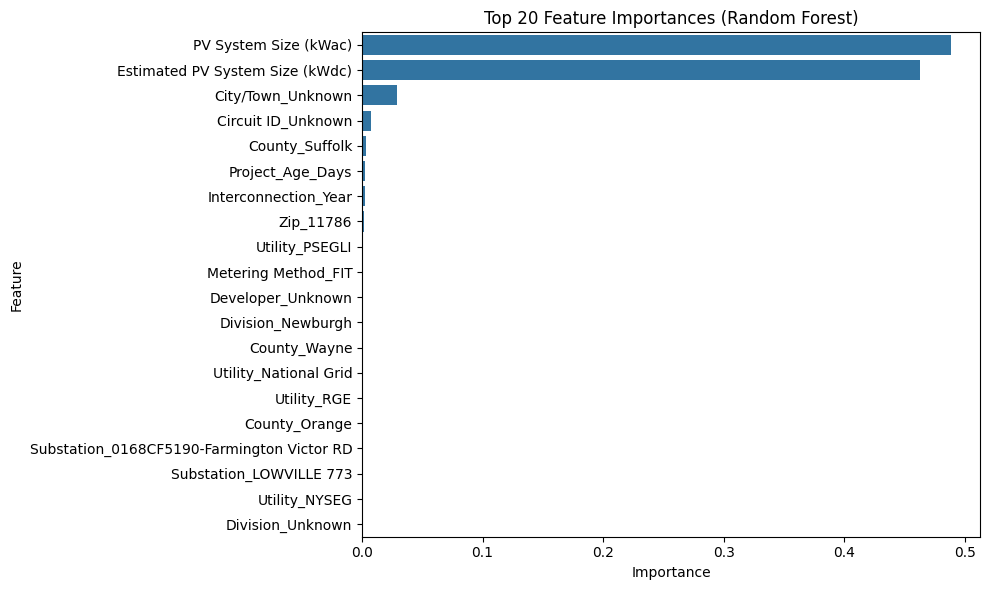

In [41]:
# Optional: Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feat_imp_df.sort_values("Importance", ascending=False)
)
plt.title("Top 20 Feature Importances (Random Forest)")
plt.tight_layout()
plt.show()


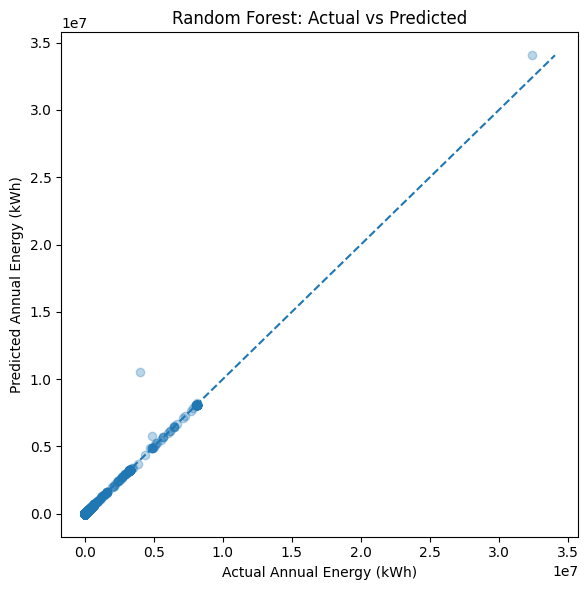

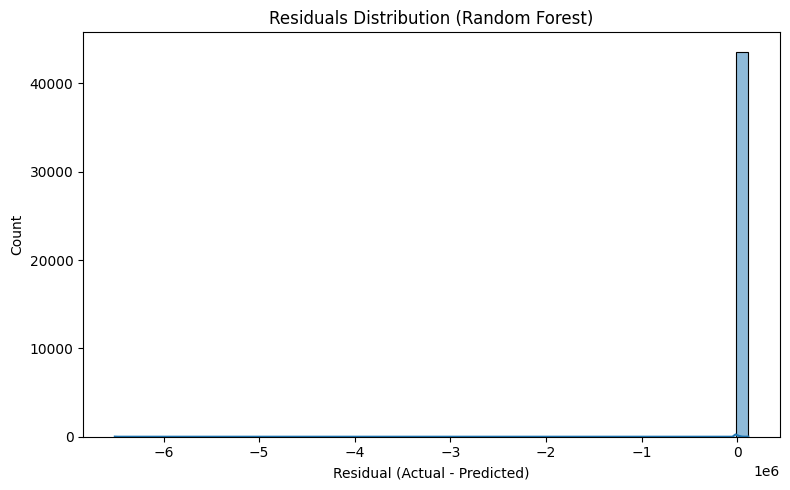

In [42]:
# ===============================
# 16. Final Evaluation Plots
# ===============================

# Scatter: Actual vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3)
plt.xlabel("Actual Annual Energy (kWh)")
plt.ylabel("Predicted Annual Energy (kWh)")
plt.title("Random Forest: Actual vs Predicted")
# 45-degree reference line
lims = [
    min(y_test.min(), y_pred_rf.min()),
    max(y_test.max(), y_pred_rf.max()),
]
plt.plot(lims, lims, "--")
plt.tight_layout()
plt.show()

# Residuals distribution
residuals = y_test - y_pred_rf
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Residuals Distribution (Random Forest)")
plt.xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()


---

In [ ]:
pip install --upgrade shap

In [ ]:
import shap

# 1. Refit RF model (if needed)
rf_model.fit(X_train, y_train)

# 2. Take a small sample for speed
X_sample = X_test.sample(300, random_state=42)

# 3. Transform sample with the preprocessor
X_sample_processed = preprocessor.transform(X_sample)
if hasattr(X_sample_processed, "toarray"):
    X_sample_processed = X_sample_processed.toarray()

# 4. Get trained RF estimator
rf = rf_model.named_steps["model"]

# 5. SHAP Explainer
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_sample_processed)

# 6. Global importance bar plot
shap.summary_plot(
    shap_values,
    X_sample_processed,
    feature_names=preprocessor.get_feature_names_out(),
    plot_type="bar"
)

# 7. Detailed summary plot
shap.summary_plot(
    shap_values,
    X_sample_processed,
    feature_names=preprocessor.get_feature_names_out()
)


### SHAP Analysis (Model Explainability)

SHAP was used to understand how each feature contributes to the Random Forest model’s predictions.

- **SHAP summary bar plot**
  - • Shows the most important features driving predictions.
  - • System size (`kWdc` and `kWac`) appears as the strongest contributor to predicted annual energy.
  - • Time-based features (e.g., project age or interconnection year) also show strong influence.
  - • Location-related categories (Utility, County, ZIP) contribute moderately.

- **SHAP summary plot**
  - • Displays how high or low feature values push predictions up or down.
  - • Larger system sizes consistently increase predicted energy output.
  - • Certain locations and developers show positive or negative effects depending on installation quality, climate, and grid conditions.

**Overall Insight:**  
SHAP confirms that the model is learning meaningful patterns — especially the strong effect of system size and key location/developer characteristics — making the Random Forest both accurate and interpretable.


# **Key Outcomes**

---

## **1. High-Accuracy Predictive Model**

The Random Forest Regressor achieved **exceptional performance**:

| **Metric** | **Value** |
|-----------|-----------|
| **MAE** | **244.91 kWh** |
| **RMSE** | **32,486.88 kWh** |
| **R² Score** | **0.9906** |

- • An **MAE of ~245 kWh** indicates extremely low average error given the scale of solar plant outputs.  
- • An **RMSE of ~32.5k kWh** shows excellent stability with minimal large-error deviations.  
- • An **R² of 0.9906** means the model explains **99.06% of all variance** in annual energy production—a near-perfect predictive fit.

This level of accuracy is suitable for **real-world financial modeling, project design, and deployment planning**.

---

## **2. Strong Feature Interpretability (SHAP Analysis)**

SHAP values provided deeper insight into model behavior:

### **Top contributors:**
- • **Estimated PV System Size (kWdc)** – strongest driver of annual kWh  
- • **PV System Size (kWac)**  
- • **Project Age / Interconnection Year**  
- • **Location-based attributes** (Utility, County, ZIP)  
- • **Developer-specific effects**

### **Key insights:**
- • Larger systems consistently push predictions upward.  
- • Certain regions/utilities show naturally higher generation patterns.  
- • Developer and design practices meaningfully influence annual energy output.  

SHAP confirms the model is **accurate, stable, and physically interpretable**.

---

# **Business Impact**

The model empowers the organization to:

- • Predict annual solar energy output with **very high confidence (R² = 0.9906)**.  
- • Improve project feasibility, reducing uncertainty in investment decisions.  
- • Optimize location selection by identifying counties/utilities with stronger production patterns.  
- • Analyze developer performance for better procurement and partnership decisions.  
- • Support grid integration using accurate energy forecasts for operational planning.  

This project positions the company as a **data-driven energy innovator**, leveraging ML to maximize ROI and support renewable expansion.

---

# **Future Work & Recommendations**

To enhance accuracy and expand operational utility:

- • Integrate **weather and irradiance data** (GHI, DNI, cloud cover).  
- • Add detailed **equipment attributes** (panel efficiency, inverter type).  
- • Explore **XGBoost, LightGBM, CatBoost** for potentially further accuracy gains.  
- • Use **time-series splits** for production-grade modeling workflows.  
- • Deploy the model as an internal **web tool or interactive dashboard**.  
- • Implement **automated model retraining** as new project data becomes available.

---

# **Final Remark**

This project showcases how strong data engineering, rigorous modeling, and modern explainability tools like **SHAP** can produce a **high-impact, highly interpretable machine learning system**.

With final model performance metrics:

- **MAE = 244.91 kWh**  
- **RMSE = 32,486.88 kWh**  
- **R² = 0.9906**

The model stands as a **powerful, production-ready solution** capable of transforming how solar projects are evaluated, planned, and optimized.


# Final Project Summary & Conclusion

This project successfully developed a highly accurate machine learning model to predict the Annual Solar Energy Production (kWh) for future PV installations. By applying structured data preprocessing, feature engineering, exploratory analysis, and advanced modeling, the project delivers a solution that is both technically robust and business impactful.